# Noise demo

Every dataset here is one centered Gaussian, so **no clusters exist**. The data are unit-normalized, as embeddings often are, and then tested two ways:

- **Test M** compares the best k-means silhouette with a Gaussian reference fitted to the normalized data. That reference ignores the normalization, so M reports clusters in noise.
- **Test W** whitens directions in a fixed random projection and compares them with uniform directions on the sphere. It should reject ~5% of the time

**Req:** Python 3.12+, with numpy, scipy, scikit-learn and matplotlib.

In [1]:
#setting
n,d,target_pr,q=28,119,2.,10
draws,repeat,n_init,seed=199,100,5,0
alpha=.05
out=None

In [2]:
import os
for v in ("OMP_NUM_THREADS","MKL_NUM_THREADS","OPENBLAS_NUM_THREADS"):
    os.environ[v]="1"
import sys,time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/"packaging/nullcal.py").exists()),None)
if ROOT is None:
    raise FileNotFoundError("packaging/nullcal.py not found; open this notebook from inside the repo")
if n<=q:
    raise ValueError("test W requires n > q")
sys.path.insert(0,str(ROOT/"packaging"))
from nullcal import participation_ratio,best_silhouette,null_test,silhouette_at_k,_gaussian_factor,_draw,_wilson
from angular_null import fixed_projection,whitened_statistic
from nullcal_validation import normalize

## tests

In [ ]:
#tune tau 
def tune_tau():
    z=np.random.default_rng(0).standard_normal((64,n,d))
    def pr(t):
        s=np.sqrt(np.exp(-np.arange(d)/t))
        return float(np.mean([participation_ratio(a*s,normalize=True) for a in z]))
    lo,hi=np.log(.05),np.log(200.)
    if not pr(np.exp(lo))<=target_pr<=pr(np.exp(hi)):
        raise ValueError("target_pr is out of reach for tau in [0.05, 200]")
    for _ in range(60):
        m=(lo+hi)/2
        if pr(np.exp(m))<target_pr:
            lo=m
        else:
            hi=m
    tau=float(np.exp((lo+hi)/2))
    return tau,pr(tau)
def null_data(tau,s):
    rng=np.random.default_rng(s)
    rot=np.linalg.qr(rng.standard_normal((d,d)))[0]
    return normalize(rng.standard_normal((n,d))@(np.sqrt(np.exp(-np.arange(d)/tau))[:,None]*rot.T))
def test_m(x,s):
    obs,k,l=best_silhouette(x,n_init=n_init,random_state=s)
    if k is None:
        return dict(p=1.,observed=obs,k=None,labels=None)
    r=null_test(x,reproject=False,match_selection=False,observed=(obs,k),n_draws=draws,n_init=n_init,seed=s)
    return dict(p=r.p,observed=obs,k=k,labels=l)
def m_reference(x,k,s):
    m,A=_gaussian_factor(normalize(x))
    rng=np.random.default_rng(s)
    return np.array([silhouette_at_k(_draw(m,A,n,rng),k,n_init=n_init,random_state=b) for b in range(draws)])
def test_w(x,P,s):
    obs,k,_=whitened_statistic(normalize(x@P),n_init)
    rng=np.random.default_rng(s)
    ref=np.array([whitened_statistic(normalize(rng.standard_normal((n,q))),n_init)[0] for _ in range(draws)])
    return dict(p=(1+np.count_nonzero(ref>=obs))/(draws+1),observed=float(obs),k=k,reference=ref)
def rate(p):
    e=int(np.sum(np.asarray(p)<alpha))
    lo,hi=_wilson(e,len(p))
    return dict(events=e,rate=e/len(p),lo=float(lo),hi=float(hi))
def verdict(p):
    return "clusters detected" if p<alpha else "no evidence of clusters"

## Run

In [4]:
t0=time.time()
if 1/(draws+1)>=alpha:
    print(f"note: the smallest p with {draws} draws is {1/(draws+1):.3f}, so nothing can reject at p < {alpha}")
tau,achieved=tune_tau()
print(f"tau = {tau:.4f}, achieved normalized participation ratio = {achieved:.4f}")
streams=[[int(v) for v in ss.generate_state(3)] for ss in np.random.SeedSequence(seed).spawn(1+repeat)]
P=fixed_projection(d,q,10000+q)

#demo
ds,ms,ws=streams[0]
x=null_data(tau,ds)
M=test_m(x,ms)
if M["k"] is None:
    raise RuntimeError("no k passes the size guard on the demo dataset; try another seed")
W=test_w(x,P,ws)
mref=m_reference(x,M["k"],ms)
assert (1+np.sum(mref>=M["observed"]))/(draws+1)==M["p"],"recomputed reference disagrees with null_test"
print(f"demo M: observed {M['observed']:.4f} at k={M['k']}, p = {M['p']:.4f}, {verdict(M['p'])}")
print(f"demo W: observed {W['observed']:.4f} at k={W['k']}, p = {W['p']:.4f}, {verdict(W['p'])}")

#null
pm,pw=[],[]
for i,(ds,ms,ws) in enumerate(streams[1:]):
    a=null_data(tau,ds)
    pm.append(test_m(a,ms)["p"]);pw.append(test_w(a,P,ws)["p"])
    if (i+1)%10==0:
        print(f"  {i+1}/{repeat} datasets, {time.time()-t0:.0f}s, M rejected {rate(pm)['events']}, W rejected {rate(pw)['events']}",flush=True)
rates=dict(M=rate(pm),W=rate(pw)) if repeat else None
if rates:
    for t,r in rates.items():
        print(f"{t}: rejected {r['events']}/{repeat} = {100*r['rate']:.1f}%, Wilson 95% [{100*r['lo']:.1f}, {100*r['hi']:.1f}]")

tau = 0.5961, achieved normalized participation ratio = 2.0000
demo M: observed 0.4372 at k=4, p = 0.0050, clusters detected
demo W: observed 0.0685 at k=4, p = 0.6450, no evidence of clusters
  10/100 datasets, 23s, M rejected 8, W rejected 1
  20/100 datasets, 42s, M rejected 18, W rejected 1
  30/100 datasets, 62s, M rejected 28, W rejected 1
  40/100 datasets, 82s, M rejected 38, W rejected 1
  50/100 datasets, 102s, M rejected 48, W rejected 1
  60/100 datasets, 122s, M rejected 58, W rejected 1
  70/100 datasets, 141s, M rejected 68, W rejected 1
  80/100 datasets, 161s, M rejected 78, W rejected 2
  90/100 datasets, 181s, M rejected 88, W rejected 2
  100/100 datasets, 201s, M rejected 98, W rejected 2
M: rejected 98/100 = 98.0%, Wilson 95% [93.0, 99.4]
W: rejected 2/100 = 2.0%, Wilson 95% [0.6, 7.0]


## Figure

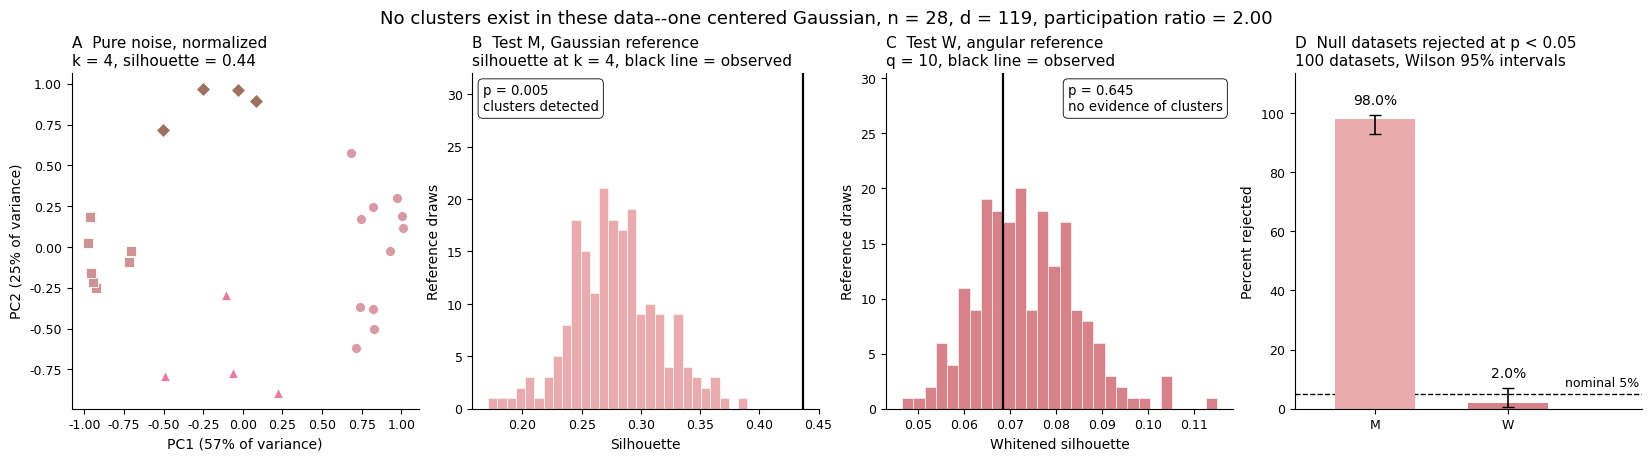

In [12]:
M_COLOR,W_COLOR,INK,MUTED="#E9ABAE","#D78289","#000000","#000000"
CLUSTERS=("#D69BA5","#CD9395","#e87ba4","#9E7060","#CA818A","#BA818B")
MARKERS=("o","s","^","D","v","P")
plt.rcParams.update({"axes.unicode_minus":False,"pdf.fonttype":42,"figure.dpi":100})
def style(ax,title,xlabel=None,ylabel=None):
    ax.set_title(title,loc="left",fontsize=11,color=INK)
    ax.set_xlabel(xlabel or "",fontsize=10,color=MUTED)
    ax.set_ylabel(ylabel or "",fontsize=10,color=MUTED)
    ax.spines[["top","right"]].set_visible(False)
    ax.spines[["left","bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED,labelsize=9)
def histogram(ax,ref,R,color,title,xlabel):
    v=ref[ref>-1]
    ax.hist(v,bins=int(np.clip(len(v)//6,6,28)),color=color,edgecolor="white",linewidth=.4)
    ax.axvline(R["observed"],color=INK,lw=1.6,zorder=3)
    ax.set_ylim(0,ax.get_ylim()[1]*1.45)
    lo,hi=ax.get_xlim()
    right=(R["observed"]-lo)/(hi-lo)<.5
    ax.text(.97 if right else .03,.97,f"p = {R['p']:.3f}\n{verdict(R['p'])}",transform=ax.transAxes,ha="right" if right else "left",va="top",multialignment="left",fontsize=9.5,color=INK,bbox=dict(boxstyle="round,pad=0.35",fc="white",ec=MUTED,lw=.6))
    style(ax,title,xlabel,"Reference draws")
f,axes=plt.subplots(1,4 if rates else 3,figsize=(4.1*(4 if rates else 3),4.5),constrained_layout=True)
#A
U,S,_=np.linalg.svd(x-x.mean(axis=0),full_matrices=False)
pc,ve=U[:,:2]*S[:2],100*S**2/np.sum(S**2)
for c in range(M["k"]):
    i=M["labels"]==c
    axes[0].scatter(pc[i,0],pc[i,1],s=52,c=CLUSTERS[c],marker=MARKERS[c],edgecolors="white",linewidths=.6,zorder=3)
style(axes[0],f"A  Pure noise, normalized\nk = {M['k']}, silhouette = {M['observed']:.2f}",f"PC1 ({ve[0]:.0f}% of variance)",f"PC2 ({ve[1]:.0f}% of variance)")
#B + C
histogram(axes[1],mref,M,M_COLOR,f"B  Test M, Gaussian reference\nsilhouette at k = {M['k']}, black line = observed","Silhouette")
histogram(axes[2],W["reference"],W,W_COLOR,f"C  Test W, angular reference\nq = {q}, black line = observed","Whitened silhouette")
#D
if rates:
    ax=axes[3]
    rs=[rates["M"],rates["W"]]
    y=[100*r["rate"] for r in rs]
    ax.bar([0,1],y,width=.6,color=[M_COLOR,W_COLOR],zorder=2)
    ax.errorbar([0,1],y,yerr=[[max(0.,100*(r["rate"]-r["lo"])) for r in rs],[max(0.,100*(r["hi"]-r["rate"])) for r in rs]],fmt="none",ecolor=INK,elinewidth=1.2,capsize=4,zorder=3)
    ax.axhline(100*alpha,color=MUTED,ls="--",lw=1,zorder=1)
    ax.text(1.98,100*alpha+1.5,f"nominal {100*alpha:.0f}%",ha="right",va="bottom",fontsize=9,color=MUTED)
    for i,r in enumerate(rs):
        ax.text(i,100*r["hi"]+2.5,f"{100*r['rate']:.1f}%",ha="center",va="bottom",fontsize=10,color=INK)
    ax.set_xticks([0,1],["M","W"])
    ax.set_xlim(-.6,2)
    ax.set_ylim(0,max(100*max(r["hi"] for r in rs)+14,20))
    style(ax,f"D  Null datasets rejected at p < {alpha}\n{repeat} datasets, Wilson 95% intervals",None,"Percent rejected")
f.suptitle(f"No clusters exist in these data--one centered Gaussian, n = {n}, d = {d}, participation ratio = {achieved:.2f}",fontsize=13,color=INK)
if out:
    f.savefig(out,dpi=200,facecolor="white")
plt.show()